In [21]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import pandas as pd
import numpy as np
from sksurv.util import Surv
from sklearn.model_selection import StratifiedGroupKFold
from sksurv.metrics import (concordance_index_censored, integrated_brier_score)
from sksurv.linear_model import CoxPHSurvivalAnalysis

from functions.preproc import *
from functions.ucphm import *

Note: the IBS horizons (2/5/10y) are hardcoded inside the function itself, not a parameter.

In [22]:
def univariate_cox_analysis(data_x, data_y, groups, n_splits):

    univariate_results = []
    # events flag, needed for the stratified splitter
    event_indicator = [y[0] for y in data_y]
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=12)

    print(f"Starting univariate analysis of {len(data_x.columns)} features...")
    print(f"Using {n_splits}-fold stratified group cross-validation")
    print("-" * 60)

    for i, feature in enumerate(data_x.columns):
        print(f"[{i+1}/{len(data_x.columns)}] Analyzing: {feature}")

        fold_results = {
            "cindex_scores": [],
            "coefficients": [],
            "brier_scores": [],
        }

        # cross-val loop for this one feature
        for fold, (train_index, test_index) in enumerate(sgkf.split(data_x, event_indicator, groups)):
            try:
                x_train_single = data_x[feature].iloc[train_index].values.reshape(-1, 1)
                x_test_single = data_x[feature].iloc[test_index].values.reshape(-1, 1)

                y_train_surv = [data_y[i] for i in train_index]
                y_test_surv = [data_y[i] for i in test_index]

                event_train = [e for e, t in y_train_surv]
                time_train = [t for e, t in y_train_surv]
                event_test = [e for e, t in y_test_surv]
                time_test = [t for e, t in y_test_surv]

                # brier needs >1 distinct time in the test fold, else skip
                if np.min(time_test) == np.max(time_test):
                    print(f"     Skipping Brier score: single time point in fold {fold}")
                    continue

                y_train = Surv.from_arrays(event=event_train, time=time_train)
                y_test = Surv.from_arrays(event=event_test, time=time_test)

                # fit univariate Cox on this feature alone
                cox_model = CoxPHSurvivalAnalysis()
                cox_model.fit(x_train_single, y_train)

                fold_results["coefficients"].append(cox_model.coef_[0])

                risk_scores = cox_model.predict(x_test_single)
                cindex = concordance_index_censored(event_test, time_test, risk_scores)[0]
                fold_results["cindex_scores"].append(cindex)

                # IBS, again at 2/5/10y
                surv_funcs = cox_model.predict_survival_function(x_test_single)
                times = np.array([2*365, 5*365, 10*365])

                surv_preds = np.asarray([[fn(t) for t in times] for fn in surv_funcs])
                if np.isnan(surv_preds).any():
                    print(f"     Skipping Brier score: NaNs in survival predictions in fold {fold}")
                    continue

                ibs = integrated_brier_score(y_train, y_test, surv_preds, times)
                fold_results["brier_scores"].append(ibs)

            except Exception as e:
                print(f"     Warning: Model fitting failed in fold {fold}: {e}")
                continue

        # skip aggregation entirely if every fold failed
        if fold_results["cindex_scores"]:
            mean_cindex = np.mean(fold_results["cindex_scores"])
            std_cindex = np.std(fold_results["cindex_scores"])

            mean_brier = np.mean(fold_results["brier_scores"]) if fold_results["brier_scores"] else np.nan
            std_brier = np.std(fold_results["brier_scores"]) if fold_results["brier_scores"] else np.nan

            mean_coef = np.mean(fold_results["coefficients"])
            std_coef = np.std(fold_results["coefficients"])

            # HR and 95% CI (delta method on the coef across folds)
            hr = np.exp(mean_coef)
            hr_lower = np.exp(mean_coef - 1.96 * std_coef)
            hr_upper = np.exp(mean_coef + 1.96 * std_coef)

            # se of mean coef -> Wald z -> two-sided p
            se_mean_coef = std_coef / np.sqrt(len(fold_results["coefficients"]))
            wald_z = mean_coef / se_mean_coef
            p_value = 2 * norm.sf(abs(wald_z)) # sf = 1 - cdf

            univariate_results.append({
                "Feature": feature,
                "C_Index_Mean": mean_cindex,
                "C_Index_Std": std_cindex,
                "Integrated_Brier_Score": mean_brier,
                "Brier_Score_Std": std_brier,
                "Coefficient_Mean": mean_coef,
                "Coefficient_Std": std_coef,
                "Hazard_Ratio": hr,
                "HR_95_CI_Lower": hr_lower,
                "HR_95_CI_Upper": hr_upper,
                "P_Value_of_HR": p_value, 
                "N_Successful_Folds": len(fold_results["cindex_scores"]),
            })

            print(f"     C-index: {mean_cindex:.4f} ± {std_cindex:.4f}")
            print(f"     Integrated Brier score: {mean_brier:.4f} ± {std_brier:.4f}")
            print(f"     HR: {hr:.4f} (95% CI: {hr_lower:.4f}–{hr_upper:.4f}), P-value: {p_value:.4f}") # Updated print
        else:
            print(f"     Failed to fit any models for {feature}")

    results_df = pd.DataFrame(univariate_results)
    return results_df

Dataset was already treated - just missing the numerical NA imputation.

In [23]:
dataset = pd.read_csv("data.csv")

In [24]:
categorical_variables = []
with open("diagnosis.txt", "r") as file:
    for line in file:
        categorical_variables.append(line.strip())

numerical_variables = []
with open("treatment.txt", "r") as file:
    for line in file:
        numerical_variables.append(line.strip())

In [25]:
feature_columns = categorical_variables + numerical_variables

In [26]:
survival_dataset = dataset.drop('Unnamed: 0', axis=1)

In [27]:
data_y = Surv.from_arrays(survival_dataset['Regional LN recurrence'], survival_dataset['Survival days'])
data_x = survival_dataset[feature_columns]
groups = survival_dataset['PERSON_ID']

In [28]:
univariate_results = univariate_cox_analysis(data_x, data_y, groups, 4)
univariate_results

Starting univariate analysis of 32 features...
Using 4-fold stratified group cross-validation
------------------------------------------------------------
[1/32] Analyzing: Age
     C-index: 0.6035 ± 0.0904
     Integrated Brier score: 0.0160 ± 0.0067
     HR: 0.9740 (95% CI: 0.9670–0.9810), P-value: 0.0000
[2/32] Analyzing: Ki67 positive cells (%) at CB
     C-index: 0.6482 ± 0.0453
     Integrated Brier score: 0.0159 ± 0.0068
     HR: 1.0167 (95% CI: 1.0153–1.0181), P-value: 0.0000
[3/32] Analyzing: Side location of the lesion
     C-index: 0.5468 ± 0.0744
     Integrated Brier score: 0.0160 ± 0.0066
     HR: 0.5997 (95% CI: 0.4162–0.8643), P-value: 0.0000
[4/32] Analyzing: Type of invasion at CB
     C-index: 0.5377 ± 0.0619
     Integrated Brier score: 0.0160 ± 0.0066
     HR: 0.5170 (95% CI: 0.3625–0.7373), P-value: 0.0000
[5/32] Analyzing: Oestrogen receptor status at CB_0.0
     C-index: 0.7285 ± 0.0430
     Integrated Brier score: 0.0157 ± 0.0066
     HR: 7.5673 (95% CI: 5.9328

,Feature,C_Index_Mean,C_Index_Std,Integrated_Brier_Score,Brier_Score_Std,Coefficient_Mean,Coefficient_Std,Hazard_Ratio,HR_95_CI_Lower,HR_95_CI_Upper,P_Value_of_HR,N_Successful_Folds
0,Age,0.603506,0.090378,0.015960,0.006716,-0.026357,0.003657,9.739875e-01,9.670320e-01,9.809930e-01,4.091204e-47,4
1,Ki67 positive cells (%) at CB,0.648233,0.045283,0.015852,0.006768,0.016572,0.000696,1.016710e+00,1.015323e+00,1.018099e+00,0.000000e+00,4
2,Side location of the lesion,0.546805,0.074403,0.015950,0.006634,-0.511251,0.186421,5.997447e-01,4.161805e-01,8.642732e-01,4.136708e-08,4
3,Type of invasion at CB,0.537747,0.061923,0.015958,0.006578,-0.659659,0.181092,5.170277e-01,3.625479e-01,7.373304e-01,3.208154e-13,4
4,Oestrogen receptor status at CB_0.0,0.728508,0.043013,0.015661,0.006586,2.023838,0.124157,7.567309e+00,5.932763e+00,9.652192e+00,3.931788e-233,4
5,Oestrogen receptor status at CB_1.0,0.789934,0.076049,0.016273,0.006565,-1.785343,0.193938,1.677395e-01,1.146971e-01,2.453117e-01,1.061807e-75,4
6,Her2 overexpression (with immunohystochemistry...,0.449028,0.056061,0.015936,0.006697,-0.032529,0.152246,9.679946e-01,7.182545e-01,1.304570e+00,6.691474e-01,4
7,Her2 overexpression (with immunohystochemistry...,0.562506,0.002637,0.015914,0.006619,-18.220020,0.007767,1.222210e-08,1.203745e-08,1.240957e-08,0.000000e+00,4
8,Her2 overexpression (with immunohystochemistry...,0.526826,0.057434,0.015915,0.006674,0.654375,0.296346,1.923940e+00,1.076308e+00,3.439112e+00,1.004106e-05,4
9,Progesterone receptor status at CB_0.0,0.651336,0.035152,0.015867,0.006696,0.998051,0.126939,2.712990e+00,2.115413e+00,3.479373e+00,1.021815e-55,4


In [14]:
univariate_results.to_csv('ucphm_diagnostic_365.csv')

In [15]:
# I have very low data of these
highlight_features = []
# in the hazard ration these are giving a very high error not sure why
new_uni = univariate_results[
    ~univariate_results['Feature'].isin(['Classification with respect to other lesions_2.0', 'Disease extent_2.0', 'Grade at CB_1.0', 'Her2 overexpression (with immunohystochemistry) at CB_2.0'])
]

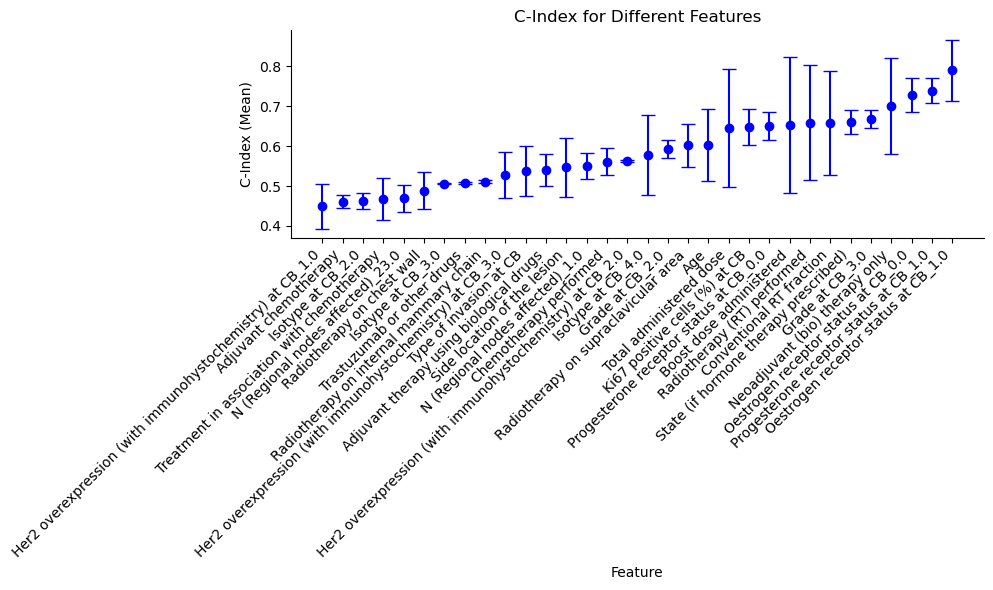

In [9]:
plot_cindex(univariate_results, 'ci_ucphm_di.png', highlight_features=[], highlight_color='red', default_color='blue')

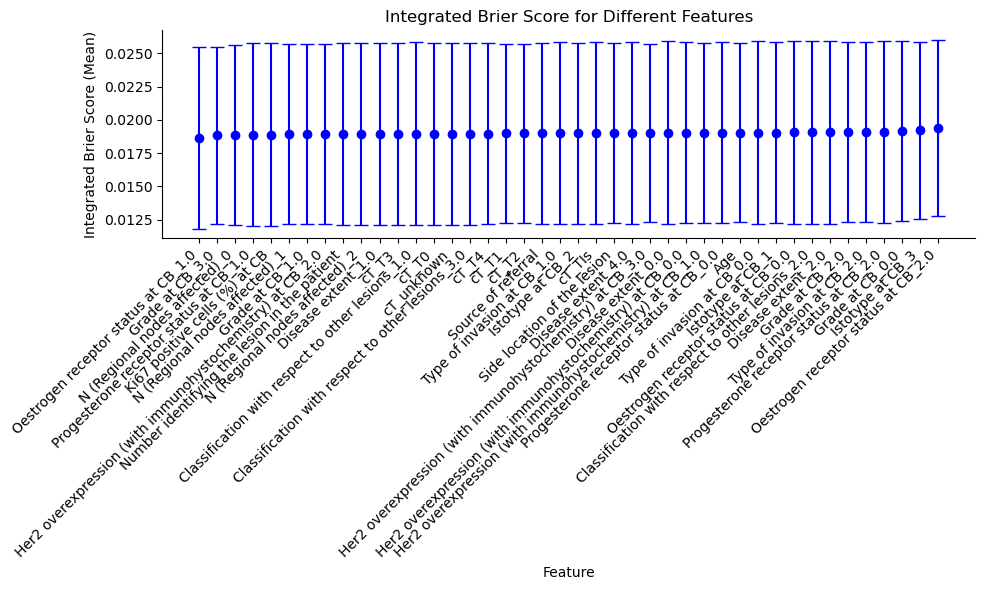

In [17]:
plot_brier(univariate_results, 'brier_ucphm_di_365.png', highlight_features=[], highlight_color='red', default_color='blue')

In [ ]:
non_significant_features = univariate_results[univariate_results['P_Value_of_HR'] >= 0.05]
non_significant_features = non_significant_features['Feature'].to_list()

In [12]:
plot_hazard(new_uni, 'hr_ucphm_di.png', highlight_features=[], highlight_color='red', default_color='blue')

NameError: name 'new_uni' is not defined

In [29]:
import pandas as pd
mean_val = univariate_results.iloc[:, 2].mean()
std_val = univariate_results.iloc[:, 2].std()
print("Mean:", mean_val)
print("Std:", std_val)
num_significant = (univariate_results['P_Value_of_HR'] < 0.05).sum()
print("Number of significant features:", num_significant)
print("Total number of features:", len(univariate_results))

Mean: 0.05612472907051615
Std: 0.04496216779404963
Number of significant features: 26
Total number of features: 32


In [30]:
univariate_results[univariate_results['P_Value_of_HR'] > 0.05]

,Feature,C_Index_Mean,C_Index_Std,Integrated_Brier_Score,Brier_Score_Std,Coefficient_Mean,Coefficient_Std,Hazard_Ratio,HR_95_CI_Lower,HR_95_CI_Upper,P_Value_of_HR,N_Successful_Folds
6,Her2 overexpression (with immunohystochemistry...,0.449028,0.056061,0.015936,0.006697,-0.032529,0.152246,0.967995,7.182545e-01,1.304570,0.669147,4
14,N (Regional nodes affected)_23.0,0.469383,0.033813,0.015960,0.006732,-3.122879,7.457821,0.044030,1.974810e-08,98169.383571,0.402324,4
15,Isotype at CB_2.0,0.462411,0.020542,0.015957,0.006690,-0.085651,0.434870,0.917914,3.914116e-01,2.152636,0.693642,4
18,Adjuvant therapy using biological drugs,0.539161,0.039938,0.015898,0.006692,-4.989224,7.660171,0.006811,2.054654e-09,22577.545398,0.192698,4
25,Treatment in association with chemotherapy,0.467139,0.052224,0.015947,0.006697,0.132508,0.193071,1.141688,7.819915e-01,1.666835,0.169867,4
27,Adjuvant chemotherapy,0.460216,0.016267,0.015919,0.006696,-0.082027,0.418178,0.921247,4.058973e-01,2.090913,0.694831,4
